# ARTI 502 Deep Learning – Assignment 1
## Training-Testing Neural Net with MNIST Dataset using PyTorch (Term 1, 2026)


### Cell 1: Install the required packages (only if needed)

In [1]:
%pip install -q torch torchvision matplotlib

### Cell 2: Import the libraries and verify the PyTorch installation

In [2]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

print("PyTorch imported successfully!")
print("PyTorch version     :", torch.__version__)
print("Torchvision version :", torchvision.__version__)
print("GPU (CUDA) available:", torch.cuda.is_available())

test_tensor = torch.tensor([1.0, 2.0, 3.0])
print("Test tensor         :", test_tensor)

PyTorch imported successfully!
PyTorch version     : 2.11.0+cpu
Torchvision version : 0.26.0+cpu
GPU (CUDA) available: False
Test tensor         : tensor([1., 2., 3.])


## Task 2 – Download and Load the MNIST Dataset
### Cell 3: Download and load the training and testing datasets

In [3]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)

test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

print("MNIST training dataset loaded successfully!")
print("MNIST testing dataset loaded successfully!")
print("Number of training images:", len(train_dataset))
print("Number of testing images :", len(test_dataset))
print("Classes (digits)         :", train_dataset.classes)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.78MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 160kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.45MB/s]

MNIST training dataset loaded successfully!
MNIST testing dataset loaded successfully!
Number of training images: 60000
Number of testing images : 10000
Classes (digits)         : ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


### Cell 4: Create the DataLoaders

In [4]:
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("DataLoaders created successfully!")
print("Batch size                 :", batch_size)
print("Number of training batches :", len(train_loader))
print("Number of testing batches  :", len(test_loader))

DataLoaders created successfully!
Batch size                 : 64
Number of training batches : 938
Number of testing batches  : 157


## Task 3 – Inspect the Dataset
### Cell 5: Inspect the tensor shapes and dimensions

In [5]:
images, labels = next(iter(train_loader))

print("Images tensor shape      :", images.shape)
print("Labels tensor shape      :", labels.shape)
print("One image tensor shape   :", images[0].shape)
print("Image data type          :", images.dtype)
print("Pixel value range        :", images.min().item(), "to", images.max().item())
print("First 10 labels in batch :", labels[:10].tolist())

print()
print("Meaning of the images tensor shape", list(images.shape))
print("  Batch size :", images.shape[0], "-> images in this batch")
print("  Channels   :", images.shape[1], "-> 1 channel = grayscale (no colour)")
print("  Height     :", images.shape[2], "-> pixels from top to bottom")
print("  Width      :", images.shape[3], "-> pixels from left to right")

Images tensor shape      : torch.Size([64, 1, 28, 28])
Labels tensor shape      : torch.Size([64])
One image tensor shape   : torch.Size([1, 28, 28])
Image data type          : torch.float32
Pixel value range        : 0.0 to 1.0
First 10 labels in batch : [2, 0, 8, 1, 9, 9, 9, 8, 2, 5]

Meaning of the images tensor shape [64, 1, 28, 28]
  Batch size : 64 -> images in this batch
  Channels   : 1 -> 1 channel = grayscale (no colour)
  Height     : 28 -> pixels from top to bottom
  Width      : 28 -> pixels from left to right


### Cell 6: Visualize the handwritten digits with Matplotlib

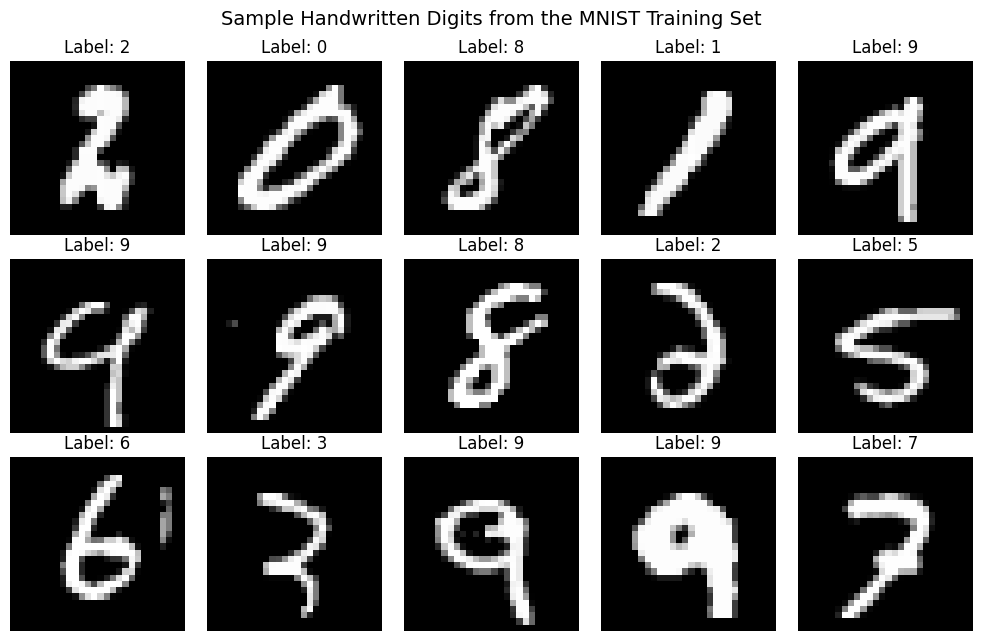

In [6]:
num_rows, num_cols = 3, 5

fig, axes = plt.subplots(num_rows, num_cols, figsize=(10, 6.5))

for i, ax in enumerate(axes.flat):
    image = images[i].squeeze().numpy()
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

fig.suptitle("Sample Handwritten Digits from the MNIST Training Set", fontsize=14)
plt.tight_layout()
plt.show()


## Task 4 – Creating a Simple Neural Network

In [7]:
import torch.nn as nn

class SimpleNeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

model = SimpleNeuralNetwork()

print(model)

SimpleNeuralNetwork(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [8]:
sample_images, sample_labels = next(iter(train_loader))

flattened_images = torch.flatten(sample_images, start_dim=1)
output_scores = model(sample_images)

print("Input images shape:", sample_images.shape)
print("After flattening:", flattened_images.shape)
print("Model output shape:", output_scores.shape)

Input images shape: torch.Size([64, 1, 28, 28])
After flattening: torch.Size([64, 784])
Model output shape: torch.Size([64, 10])


## Task 5 – Training Function

In [9]:

import torch.optim as optim

def train(net, train_loader, epochs=5, learning_rate=0.01, momentum=0.9):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=learning_rate, momentum=momentum)
    losses = []
    accuracies = []
    for epoch in range(epochs):
        net.train()
        correct = 0
        total = 0
        for batch, (images, labels) in enumerate(train_loader):
            optimizer.zero_grad()
            outputs = net(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
            predicted = outputs.argmax(dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            if (batch + 1) % 100 == 0:
                print("Epoch:", epoch + 1, "Batch:", batch + 1,"Loss:", round(loss.item(), 4),"Accuracy:", round(100 * correct / total, 2), "%")
        accuracies.append(100 * correct / total)
    return losses, accuracies

## Task 6 – Training Network

In [10]:

model = SimpleNeuralNetwork()
losses, accuracies = train(model, train_loader)


Epoch: 1 Batch: 100 Loss: 0.708 Accuracy: 63.41 %
Epoch: 1 Batch: 200 Loss: 0.4839 Accuracy: 74.91 %
Epoch: 1 Batch: 300 Loss: 0.1595 Accuracy: 79.62 %
Epoch: 1 Batch: 400 Loss: 0.5381 Accuracy: 82.03 %
Epoch: 1 Batch: 500 Loss: 0.3308 Accuracy: 83.62 %
Epoch: 1 Batch: 600 Loss: 0.1755 Accuracy: 84.75 %
Epoch: 1 Batch: 700 Loss: 0.3186 Accuracy: 85.66 %
Epoch: 1 Batch: 800 Loss: 0.2215 Accuracy: 86.42 %
Epoch: 1 Batch: 900 Loss: 0.3522 Accuracy: 87.04 %
Epoch: 2 Batch: 100 Loss: 0.2344 Accuracy: 92.52 %
Epoch: 2 Batch: 200 Loss: 0.2941 Accuracy: 92.73 %
Epoch: 2 Batch: 300 Loss: 0.2758 Accuracy: 92.85 %
Epoch: 2 Batch: 400 Loss: 0.328 Accuracy: 92.9 %
Epoch: 2 Batch: 500 Loss: 0.1717 Accuracy: 93.09 %
Epoch: 2 Batch: 600 Loss: 0.1284 Accuracy: 93.18 %
Epoch: 2 Batch: 700 Loss: 0.2934 Accuracy: 93.25 %
Epoch: 2 Batch: 800 Loss: 0.1821 Accuracy: 93.26 %
Epoch: 2 Batch: 900 Loss: 0.1272 Accuracy: 93.36 %
Epoch: 3 Batch: 100 Loss: 0.1189 Accuracy: 94.66 %
Epoch: 3 Batch: 200 Loss: 0.2114 A

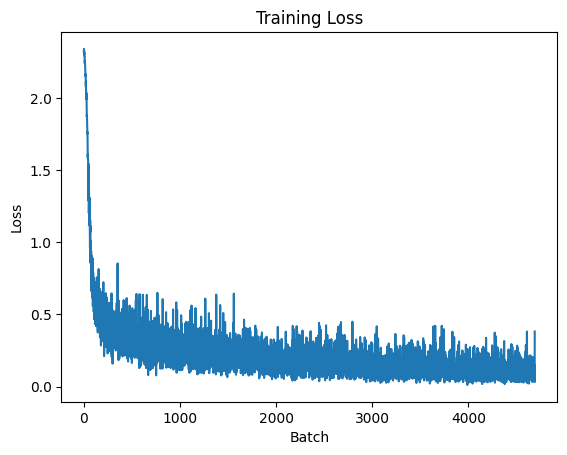

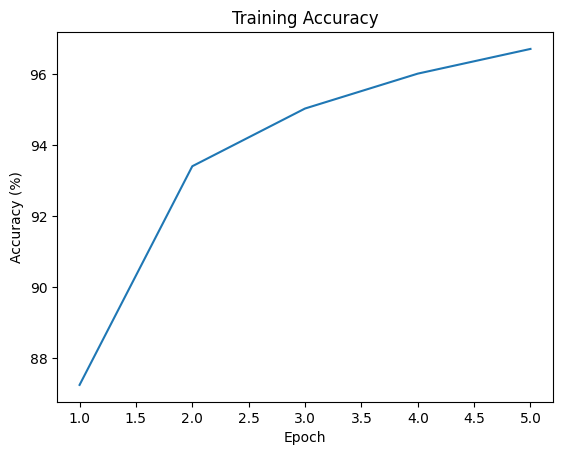

In [11]:

plt.plot(losses)
plt.xlabel("Batch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()
plt.plot(range(1, len(accuracies) + 1), accuracies)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training Accuracy")
plt.show()


## Task 7 - Testing the Trained Network



In [12]:
model.eval()
device = next(model.parameters()).device
criterion = nn.CrossEntropyLoss()
test_loss_sum = 0.0
correct = 0
total = 0

with torch.no_grad():
    for test_images, test_labels in test_loader:
        test_images = test_images.to(device)
        test_labels = test_labels.to(device)
        test_outputs = model(test_images)
        test_loss = criterion(test_outputs, test_labels)
        test_predictions = test_outputs.argmax(dim=1)
        test_loss_sum += test_loss.item() * test_labels.size(0)
        correct += (test_predictions == test_labels).sum().item()
        total += test_labels.size(0)

test_accuracy = 100 * correct / total
average_test_loss = test_loss_sum / total
print("Number of test images:", total)
print("Correct predictions:", correct)
print(f"Test accuracy: {test_accuracy:.2f}%")
print(f"Average test loss: {average_test_loss:.4f}")

Number of test images: 10000
Correct predictions: 9660
Test accuracy: 96.60%
Average test loss: 0.1130


### Display predictions for ten test images


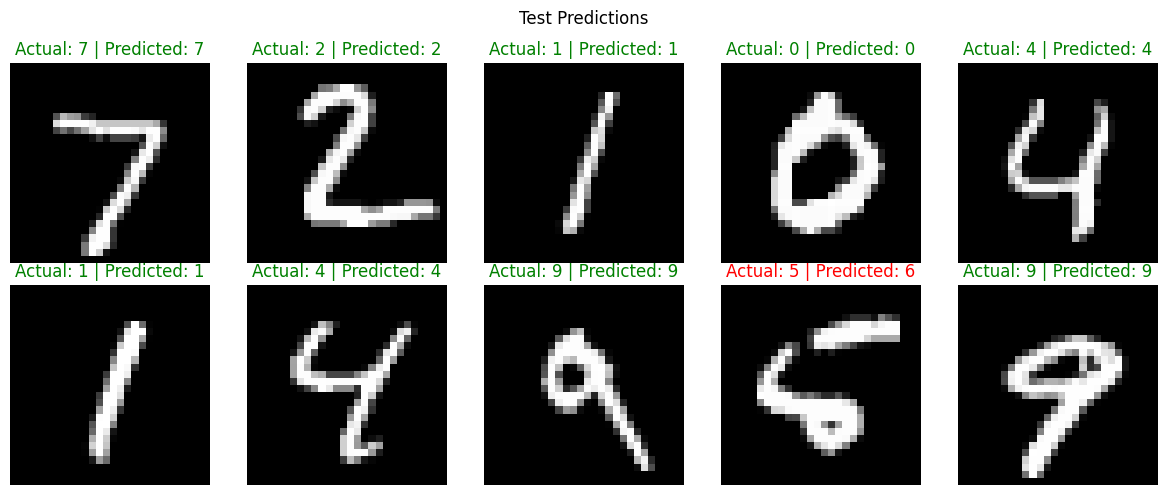

Image | Actual | Predicted | Result
1 | 7 | 7 | Correct
2 | 2 | 2 | Correct
3 | 1 | 1 | Correct
4 | 0 | 0 | Correct
5 | 4 | 4 | Correct
6 | 1 | 1 | Correct
7 | 4 | 4 | Correct
8 | 9 | 9 | Correct
9 | 5 | 6 | Incorrect
10 | 9 | 9 | Correct


In [13]:
test_images, test_labels = next(iter(test_loader))
model.eval()
with torch.no_grad():
    test_outputs = model(test_images.to(device))
    test_predictions = test_outputs.argmax(dim=1).cpu()

num_images = min(10, len(test_labels))
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.axis("off")
    if i >= num_images:
        continue
    actual = test_labels[i].item()
    predicted = test_predictions[i].item()
    ax.imshow(test_images[i].squeeze().cpu().numpy(), cmap="gray")
    ax.set_title(f"Actual: {actual} | Predicted: {predicted}",
                 color="green" if actual == predicted else "red")
fig.suptitle("Test Predictions")
plt.tight_layout()
plt.show()

print("Image | Actual | Predicted | Result")
for i in range(num_images):
    actual = test_labels[i].item()
    predicted = test_predictions[i].item()
    result = "Correct" if actual == predicted else "Incorrect"
    print(i + 1, "|", actual, "|", predicted, "|", result)


## Task 8 - Part 1: Hyperparameter Tuning

In [14]:
import torch
import torch.nn as nn

# Different learning rates and momentum values
experiments = [
    {"learning_rate": 0.1,  "momentum": 0.0},
    {"learning_rate": 0.1,  "momentum": 0.9},
    {"learning_rate": 0.01, "momentum": 0.0},
    {"learning_rate": 0.01, "momentum": 0.9},
]

results = []

for exp in experiments:
    lr = exp["learning_rate"]
    mom = exp["momentum"]

    print(f"\nTesting learning_rate={lr}, momentum={mom}")

    # Create a fresh model for a fair comparison
    model = SimpleNeuralNetwork()

    # Train using the existing training function
    losses, accuracies = train(
        model,
        train_loader,
        epochs=3,
        learning_rate=lr,
        momentum=mom
    )

    # Evaluate on the test dataset
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    test_loss = total_loss / total
    test_accuracy = 100 * correct / total

    results.append({
        "learning_rate": lr,
        "momentum": mom,
        "training_loss": losses[-1],
        "training_accuracy": accuracies[-1],
        "test_loss": test_loss,
        "test_accuracy": test_accuracy
    })

# Display the comparison
import pandas as pd

results_df = pd.DataFrame(results)
print("\nHyperparameter Tuning Results:")
display(results_df.round(4))

# Select the best result based on test accuracy
best_result = max(results, key=lambda x: x["test_accuracy"])

print("\nBest Hyperparameter Combination:")
print("Learning rate:", best_result["learning_rate"])
print("Momentum:", best_result["momentum"])
print("Test loss:", round(best_result["test_loss"], 4))
print("Test accuracy:", round(best_result["test_accuracy"], 2), "%")



Testing learning_rate=0.1, momentum=0.0
Epoch: 1 Batch: 100 Loss: 0.5641 Accuracy: 69.33 %
Epoch: 1 Batch: 200 Loss: 0.5292 Accuracy: 78.52 %
Epoch: 1 Batch: 300 Loss: 0.483 Accuracy: 81.74 %
Epoch: 1 Batch: 400 Loss: 0.1364 Accuracy: 83.81 %
Epoch: 1 Batch: 500 Loss: 0.497 Accuracy: 85.2 %
Epoch: 1 Batch: 600 Loss: 0.2357 Accuracy: 86.18 %
Epoch: 1 Batch: 700 Loss: 0.1652 Accuracy: 86.98 %
Epoch: 1 Batch: 800 Loss: 0.4624 Accuracy: 87.55 %
Epoch: 1 Batch: 900 Loss: 0.2175 Accuracy: 88.08 %
Epoch: 2 Batch: 100 Loss: 0.3632 Accuracy: 92.67 %
Epoch: 2 Batch: 200 Loss: 0.1411 Accuracy: 92.99 %
Epoch: 2 Batch: 300 Loss: 0.2164 Accuracy: 93.01 %
Epoch: 2 Batch: 400 Loss: 0.3101 Accuracy: 93.11 %
Epoch: 2 Batch: 500 Loss: 0.0941 Accuracy: 93.14 %
Epoch: 2 Batch: 600 Loss: 0.2096 Accuracy: 93.22 %
Epoch: 2 Batch: 700 Loss: 0.1865 Accuracy: 93.31 %
Epoch: 2 Batch: 800 Loss: 0.3555 Accuracy: 93.4 %
Epoch: 2 Batch: 900 Loss: 0.1848 Accuracy: 93.53 %
Epoch: 3 Batch: 100 Loss: 0.0986 Accuracy: 95

,learning_rate,momentum,training_loss,training_accuracy,test_loss,test_accuracy
0,0.10,0.0,0.0950,95.1217,0.1484,95.63
1,0.10,0.9,0.0647,97.5583,0.1027,96.74
2,0.01,0.0,0.4770,89.2583,0.3520,90.00
3,0.01,0.9,0.1362,95.0550,0.1564,95.44



Best Hyperparameter Combination:
Learning rate: 0.1
Momentum: 0.9
Test loss: 0.1027
Test accuracy: 96.74 %


## Task 8 - Part 2: Model Architecture Tuning

In [15]:
import torch
import torch.nn as nn
import pandas as pd
import torch.optim as optim

class TunableNeuralNetwork(nn.Module):
    def __init__(self, hidden_sizes):
        super().__init__()

        layers = [nn.Flatten()]
        input_size = 28 * 28

        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(input_size, hidden_size))
            layers.append(nn.ReLU())
            input_size = hidden_size

        layers.append(nn.Linear(input_size, 10))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


# Compare different architectures
architectures = [
    {"name": "64 neurons", "hidden_sizes": [64]},
    {"name": "128 neurons", "hidden_sizes": [128]},
    {"name": "256 neurons", "hidden_sizes": [256]},
    {"name": "Two hidden layers", "hidden_sizes": [128, 64]},
]

architecture_results = []

for arch in architectures:
    print(f"\nTesting architecture: {arch['name']}")

    model = TunableNeuralNetwork(arch["hidden_sizes"])

    losses, accuracies = train(
        model,
        train_loader,
        epochs=3,
        learning_rate=0.1,
        momentum=0.9
    )

    # Evaluate on the test dataset
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    architecture_results.append({
        "architecture": arch["name"],
        "hidden_layers": len(arch["hidden_sizes"]),
        "neurons": str(arch["hidden_sizes"]),
        "test_loss": total_loss / total,
        "test_accuracy": 100 * correct / total
    })

architecture_df = pd.DataFrame(architecture_results)

print("\nArchitecture Tuning Results:")
display(architecture_df.round(4))

best_architecture = min(
    architecture_results,
    key=lambda x: (x["test_loss"], -x["test_accuracy"])
)

print("\nBest Architecture:")
print("Architecture:", best_architecture["architecture"])
print("Test loss:", round(best_architecture["test_loss"], 4))
print("Test accuracy:", round(best_architecture["test_accuracy"], 2), "%")



Testing architecture: 64 neurons
Epoch: 1 Batch: 100 Loss: 0.4498 Accuracy: 77.12 %
Epoch: 1 Batch: 200 Loss: 0.2591 Accuracy: 84.04 %
Epoch: 1 Batch: 300 Loss: 0.3533 Accuracy: 86.78 %
Epoch: 1 Batch: 400 Loss: 0.2299 Accuracy: 88.58 %
Epoch: 1 Batch: 500 Loss: 0.135 Accuracy: 89.59 %
Epoch: 1 Batch: 600 Loss: 0.2374 Accuracy: 90.32 %
Epoch: 1 Batch: 700 Loss: 0.193 Accuracy: 90.86 %
Epoch: 1 Batch: 800 Loss: 0.126 Accuracy: 91.29 %
Epoch: 1 Batch: 900 Loss: 0.1441 Accuracy: 91.74 %
Epoch: 2 Batch: 100 Loss: 0.0335 Accuracy: 95.8 %
Epoch: 2 Batch: 200 Loss: 0.1355 Accuracy: 95.73 %
Epoch: 2 Batch: 300 Loss: 0.0752 Accuracy: 95.73 %
Epoch: 2 Batch: 400 Loss: 0.0634 Accuracy: 95.87 %
Epoch: 2 Batch: 500 Loss: 0.1072 Accuracy: 96.08 %
Epoch: 2 Batch: 600 Loss: 0.1055 Accuracy: 96.16 %
Epoch: 2 Batch: 700 Loss: 0.0628 Accuracy: 96.16 %
Epoch: 2 Batch: 800 Loss: 0.0995 Accuracy: 96.18 %
Epoch: 2 Batch: 900 Loss: 0.1045 Accuracy: 96.19 %
Epoch: 3 Batch: 100 Loss: 0.0286 Accuracy: 96.61 %
E

,architecture,hidden_layers,neurons,test_loss,test_accuracy
0,64 neurons,1,[64],0.1159,96.68
1,128 neurons,1,[128],0.0912,97.23
2,256 neurons,1,[256],0.0843,97.37
3,Two hidden layers,2,"[128, 64]",0.1540,95.71



Best Architecture:
Architecture: 256 neurons
Test loss: 0.0843
Test accuracy: 97.37 %
